# Notebook 07 — Future Spending and Revenue Forecasting

**Project:** Customer Segmentation and Retention Intelligence  
**Data:** Online Retail II, Year 1 only  
**Purpose:** Forecast total gross revenue over 30, 60, and 90 days with a historical-rate baseline, a segment-aware conditional mean, and a personalized Ridge model.

This notebook uses Notebook 05's outcome-matured horizon-specific splits. Notebook 06's saved purchase-clock model supplies personalized purchase probabilities for the validation and test cutoffs only. Its saved TEST prediction CSV is not reused. The spending models are fitted from TRAIN customers and selected with VAL only; TEST outcomes are opened after selection.

## 1. Forecast design and guardrails

The conditional models use the two-stage expectation `P(purchase within H) × E(total gross revenue within H | purchase within H)`. The conditional target is the sum of all valid order revenue in `(cutoff, cutoff + H]`, not the first order amount. Model A is a direct historical spending-rate baseline. Model B estimates purchaser-only conditional means by historical segment and shrinks sparse segments toward the TRAIN global mean. Model C fits `log1p(FutureRevenue_Hd)` using a preprocessing pipeline fitted on positive-activity TRAIN customers only; alpha is selected on VAL purchasers and log predictions are retransformed with a TRAIN-only out-of-fold Duan smearing factor.

The historical-rate baseline adds 30 days of pooled TRAIN exposure before estimating an individual rate, which stabilizes customers with short tenure. Its rate cap is the TRAIN 99th percentile of shrunk rates. For Ridge, the numeric pipeline uses TRAIN median imputation, log1p, TRAIN-only 1st/99th percentile clipping, and scaling; this limits extrapolation from extremely short exposure rates without removing customers or future outcomes. Test sensitivity analyses show how the largest spenders affect error metrics.

Notebook 06's model was trained on the 90-day TRAIN cohort whose outcome window matured by 2010-05-30. Every spending VAL and TEST cutoff is later than that date. We regenerate predictions from the saved model for each exact horizon-specific customer/cutoff cohort. No Notebook 06 TRAIN predictions are used, and no purchase probability is used to fit conditional spending models.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "src" / "spending_model.py").exists():
        PROJECT_ROOT = candidate
        break
    if (candidate / "OELP_project" / "src" / "spending_model.py").exists():
        PROJECT_ROOT = candidate / "OELP_project"
        break
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from the OELP_project directory.")
sys.path.insert(0, str(PROJECT_ROOT))
from src import purchase_clock as pc
from src import spending_model as sm
from src import temporal_framework as tf

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TEMPORAL_DIR = DATA_DIR / "temporal"
PURCHASE_MODEL_DIR = PROJECT_ROOT / "models" / "purchase_clock"
MODEL_DIR = PROJECT_ROOT / "models" / "spending_model"
OUTPUT_DIR = DATA_DIR / "spending_forecast"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

with (TEMPORAL_DIR / "temporal_split_metadata.json").open(encoding="utf-8") as f:
    temporal_metadata = json.load(f)
with (PURCHASE_MODEL_DIR / "metadata.json").open(encoding="utf-8") as f:
    purchase_metadata = json.load(f)
orders = pd.read_csv(TEMPORAL_DIR / "orders.csv", parse_dates=["PurchaseDate"])
dataset_end = orders["PurchaseDate"].max()
purchase_bundle = pc.load_purchase_clock_artifacts(PURCHASE_MODEL_DIR)

assert orders["Customer ID"].isin(tf.ADMIN_EXCLUDE).sum() == 0
assert (~orders["Invoice"].astype(str).str.startswith("C")).all()
assert purchase_metadata["training_cutoff"] == "2010-03-01"
assert purchase_metadata["training_split_file"].endswith("predictive_splits_90d.csv")
print(f"Order rows: {len(orders):,}; Year 1 data end: {dataset_end}")
print(f"Loaded purchase-clock bundle: {purchase_metadata['model_version']}")

Order rows: 19,213; Year 1 data end: 2010-12-09 20:01:00
Loaded purchase-clock bundle: purchase-clock-v1


## 2. Load horizon-specific historical features

Only cutoff-time predictors and split labels are loaded at this stage. Future revenue is reconstructed from the order table for TRAIN and VAL in the next section. TEST historical features are loaded without any TEST target columns.

In [2]:
EXPECTED_CUTOFFS = {
    30: {"TRAIN": "2010-06-01", "VAL": "2010-08-01", "TEST": "2010-09-10"},
    60: {"TRAIN": "2010-05-01", "VAL": "2010-07-01", "TEST": "2010-09-10"},
    90: {"TRAIN": "2010-03-01", "VAL": "2010-06-01", "TEST": "2010-09-10"},
}
feature_frames = {}
split_paths = {}
for horizon in sm.HORIZONS:
    split_path = TEMPORAL_DIR / f"predictive_splits_{horizon}d.csv"
    split_paths[horizon] = split_path
    split = pd.read_csv(
        split_path,
        usecols=[*sm.FEATURE_COLUMNS, "split_role", "horizon_days"],
        parse_dates=["cutoff_date"],
    )
    assert set(split["split_role"].unique()) == {"TRAIN", "VAL", "TEST"}
    assert split["horizon_days"].eq(horizon).all()
    feature_frames[horizon] = {}
    for role, expected_date in EXPECTED_CUTOFFS[horizon].items():
        role_frame = split.loc[split["split_role"].eq(role), list(sm.FEATURE_COLUMNS)].copy()
        role_frame = sm.validate_features(role_frame)
        expected_cutoff = pd.Timestamp(expected_date)
        assert role_frame["cutoff_date"].nunique() == 1
        assert role_frame["cutoff_date"].iloc[0] == expected_cutoff
        assert expected_cutoff + pd.Timedelta(days=horizon) <= dataset_end
        feature_frames[horizon][role] = role_frame
    print(
        f"{horizon}d — TRAIN {len(feature_frames[horizon]['TRAIN']):,}; "
        f"VAL {len(feature_frames[horizon]['VAL']):,}; "
        f"TEST {len(feature_frames[horizon]['TEST']):,}; "
        f"cutoffs {EXPECTED_CUTOFFS[horizon]}"
    )

# All head-to-head TEST methods share the same customers and cutoff.
test_keys = feature_frames[90]["TEST"][[sm.CUSTOMER_ID, sm.CUTOFF_COL]].sort_values(sm.CUSTOMER_ID).reset_index(drop=True)
for horizon in (30, 60):
    other_keys = feature_frames[horizon]["TEST"][[sm.CUSTOMER_ID, sm.CUTOFF_COL]].sort_values(sm.CUSTOMER_ID).reset_index(drop=True)
    assert test_keys.equals(other_keys)
print("TEST customer/cutoff cohort matches across all horizons.")

30d — TRAIN 2,703; VAL 3,159; TEST 3,373; cutoffs {'TRAIN': '2010-06-01', 'VAL': '2010-08-01', 'TEST': '2010-09-10'}
60d — TRAIN 2,449; VAL 2,973; TEST 3,373; cutoffs {'TRAIN': '2010-05-01', 'VAL': '2010-07-01', 'TEST': '2010-09-10'}
90d — TRAIN 1,712; VAL 2,703; TEST 3,373; cutoffs {'TRAIN': '2010-03-01', 'VAL': '2010-06-01', 'TEST': '2010-09-10'}
TEST customer/cutoff cohort matches across all horizons.


## 3. Build TRAIN and VAL spending outcomes

The split files' outcome-matured schedule is checked against Notebook 05. Outcomes are generated only for TRAIN and VAL cohorts here. TEST outcomes remain unopened until all three alpha selections and validation comparisons are complete.

In [3]:
maturity = temporal_metadata["predictive_splits_outcome_matured"]
purchase_train_end = pd.Timestamp(maturity["90"]["train_target_end"])
assert purchase_train_end == pd.Timestamp("2010-05-30")
targets_by_role = {}
for horizon in sm.HORIZONS:
    schedule = maturity[str(horizon)]
    assert pd.Timestamp(schedule["train_target_end"]) <= pd.Timestamp(EXPECTED_CUTOFFS[horizon]["VAL"])
    assert pd.Timestamp(schedule["val_target_end"]) <= pd.Timestamp(EXPECTED_CUTOFFS[horizon]["TEST"])
    for role in ("TRAIN", "VAL"):
        features = feature_frames[horizon][role]
        cutoff = pd.Timestamp(EXPECTED_CUTOFFS[horizon][role])
        targets = tf.compute_future_targets(
            orders, features, cutoff, dataset_end, horizons=[horizon]
        )
        target_columns = [
            sm.CUSTOMER_ID,
            f"FutureRevenue_{horizon}d",
            f"FutureOrders_{horizon}d",
            f"Purchased_{horizon}d",
        ]
        targets = targets[target_columns].copy()
        assert targets[f"Purchased_{horizon}d"].notna().all()
        assert (targets[f"Purchased_{horizon}d"] == (targets[f"FutureOrders_{horizon}d"] > 0).astype(int)).all()
        targets_by_role[(horizon, role)] = targets
        print(
            f"{horizon}d {role}: {len(features):,} eligible; "
            f"{int((targets[f'FutureOrders_{horizon}d'] > 0).sum()):,} with future orders; "
            f"total future gross revenue £{targets[f'FutureRevenue_{horizon}d'].sum():,.2f}"
        )

# All VAL cutoffs are after the last outcome used to fit Notebook 06.
for horizon in sm.HORIZONS:
    val_cutoff = pd.Timestamp(EXPECTED_CUTOFFS[horizon]["VAL"])
    assert val_cutoff > purchase_train_end
    assert pd.Timestamp(EXPECTED_CUTOFFS[horizon]["TEST"]) > purchase_train_end
print("Notebook 06 training outcomes mature before every spending VAL/TEST prediction cutoff.")

30d TRAIN: 2,703 eligible; 771 with future orders; total future gross revenue £505,326.77
30d VAL: 3,159 eligible; 730 with future orders; total future gross revenue £520,627.14
60d TRAIN: 2,449 eligible; 1,103 with future orders; total future gross revenue £953,861.21
60d VAL: 2,973 eligible; 1,127 with future orders; total future gross revenue £1,027,114.93
90d TRAIN: 1,712 eligible; 1,058 with future orders; total future gross revenue £1,288,978.51


90d VAL: 2,703 eligible; 1,339 with future orders; total future gross revenue £1,493,881.63
Notebook 06 training outcomes mature before every spending VAL/TEST prediction cutoff.


## 4. Fit spending models and select Ridge alpha on VAL only

Each horizon gets its own model, target, and matured split. The fit API accepts TRAIN and VAL only; it has no TEST argument. Ridge selection minimizes conditional purchaser RMSE on VAL, with higher alpha as the deterministic tie-break. The training pipeline handles missing median gaps through TRAIN-fitted imputation and missingness indicators.

In [4]:
horizon_models = {}
selection_tables = []
validation_forecasts = []
validation_actuals = []
validation_conditional_rows = []
purchase_probability_validation = {}

def forecast_rows(wide_predictions, horizon, split_role):
    """Convert inference-only model outputs to a compact model-long schema."""
    suffix = f"{horizon}d"
    key_columns = [sm.CUSTOMER_ID, sm.CUTOFF_COL]
    base = wide_predictions[key_columns].copy()
    base["split_role"] = split_role
    base["horizon_days"] = horizon
    probability = wide_predictions[f"purchase_probability_{suffix}"].to_numpy(dtype=float)
    definitions = [
        ("Historical spending-rate", f"historical_rate_expected_{suffix}", np.full(len(base), np.nan)),
        ("Segment-aware two-stage", f"segment_expected_revenue_{suffix}", wide_predictions[f"segment_conditional_revenue_{suffix}"].to_numpy(dtype=float)),
        ("Personalized two-stage", f"personalized_expected_revenue_{suffix}", wide_predictions[f"personalized_conditional_revenue_{suffix}"].to_numpy(dtype=float)),
    ]
    rows = []
    for model_name, prediction_column, conditional in definitions:
        row = base.copy()
        row["model"] = model_name
        row["purchase_probability"] = probability
        row["predicted_conditional_revenue"] = conditional
        row["predicted_expected_revenue"] = wide_predictions[prediction_column].to_numpy(dtype=float)
        rows.append(row)
    return pd.concat(rows, ignore_index=True)

def actual_rows(targets, horizon, split_role, cutoff):
    return pd.DataFrame({
        sm.CUSTOMER_ID: targets[sm.CUSTOMER_ID].to_numpy(),
        sm.CUTOFF_COL: pd.Timestamp(cutoff),
        "split_role": split_role,
        "horizon_days": horizon,
        "actual_future_revenue": targets[f"FutureRevenue_{horizon}d"].to_numpy(dtype=float),
        "actual_future_orders": targets[f"FutureOrders_{horizon}d"].to_numpy(dtype=int),
        "actual_purchased": targets[f"Purchased_{horizon}d"].to_numpy(dtype=int),
    })

for horizon in sm.HORIZONS:
    train_features = feature_frames[horizon]["TRAIN"]
    val_features = feature_frames[horizon]["VAL"]
    train_targets = targets_by_role[(horizon, "TRAIN")]
    val_targets = targets_by_role[(horizon, "VAL")]
    fitted = sm.fit_horizon_models(
        train_features, train_targets, val_features, val_targets, horizon,
        alpha_candidates=sm.DEFAULT_ALPHA_CANDIDATES,
    )
    horizon_models[horizon] = fitted
    selection = fitted["personalized_conditional"]["selection_metrics"].copy()
    selection["selected"] = selection["alpha"].eq(fitted["personalized_conditional"]["alpha"])
    selection_tables.append(selection)

    # Fresh VAL predictions from Notebook 06's saved model, not its TEST CSV.
    val_purchase = pc.predict_purchase_clock(purchase_bundle, val_features)
    assert val_purchase[[sm.CUSTOMER_ID, sm.CUTOFF_COL]].equals(
        val_features[[sm.CUSTOMER_ID, sm.CUTOFF_COL]].reset_index(drop=True)
    )
    purchase_probability_validation[horizon] = val_purchase
    one_horizon_bundle = {
        "metadata": {"model_version": sm.MODEL_VERSION},
        "horizon_models": {horizon: fitted},
    }
    val_wide = sm.predict_expected_revenue(one_horizon_bundle, val_features, val_purchase)
    validation_forecasts.append(forecast_rows(val_wide, horizon, "VAL"))
    validation_actuals.append(
        actual_rows(val_targets, horizon, "VAL", EXPECTED_CUTOFFS[horizon]["VAL"])
    )
    buyers = val_targets[f"FutureOrders_{horizon}d"].to_numpy(dtype=int) > 0
    actual_buyer_revenue = val_targets.loc[buyers, f"FutureRevenue_{horizon}d"].to_numpy(dtype=float)
    for label, column in [
        ("Segment-aware conditional", f"segment_conditional_revenue_{horizon}d"),
        ("Personalized conditional", f"personalized_conditional_revenue_{horizon}d"),
    ]:
        conditional = sm.evaluate_conditional_spending(
            actual_buyer_revenue, val_wide.loc[buyers, column].to_numpy(dtype=float)
        )
        validation_conditional_rows.append({"horizon_days": horizon, "model": label, **conditional})

    print(
        f"{horizon}d: TRAIN buyers={fitted['personalized_conditional']['training_purchasers']:,}; "
        f"VAL buyers={fitted['personalized_conditional']['validation_purchasers']:,}; "
        f"selected Ridge alpha={fitted['personalized_conditional']['alpha']:g}; "
        f"TRAIN smearing={fitted['personalized_conditional']['smearing_factor']:.4f}"
    )

validation_forecasts = pd.concat(validation_forecasts, ignore_index=True)
validation_actuals = pd.concat(validation_actuals, ignore_index=True)
validation_selection_metrics = pd.concat(selection_tables, ignore_index=True)
validation_conditional_metrics = pd.DataFrame(validation_conditional_rows)
assert not set(sm.FORBIDDEN_FEATURES).intersection(sm.FEATURE_COLUMNS)
assert all(model["personalized_conditional"]["training_purchasers"] > 0 for model in horizon_models.values())
print("All preprocessing and fitting used TRAIN only; alpha selection used VAL only.")

30d: TRAIN buyers=771; VAL buyers=730; selected Ridge alpha=0.1; TRAIN smearing=1.3083


60d: TRAIN buyers=1,103; VAL buyers=1,127; selected Ridge alpha=10; TRAIN smearing=1.2823


90d: TRAIN buyers=1,058; VAL buyers=1,339; selected Ridge alpha=0.1; TRAIN smearing=1.3416
All preprocessing and fitting used TRAIN only; alpha selection used VAL only.


## 5. Validation comparison

The validation head-to-head uses the same eligible VAL customers for all three expected-revenue methods within each horizon. Conditional amount metrics are reported only among customers who actually had at least one valid future order.

In [5]:
def score_expected_forecasts(forecasts, actuals):
    joined = forecasts.merge(
        actuals,
on=[sm.CUSTOMER_ID, sm.CUTOFF_COL, "split_role", "horizon_days"],
        how="inner",
validate="many_to_one",
    )
    if len(joined) != len(forecasts):
        raise ValueError("Forecast and evaluation cohorts did not align exactly.")
    rows = []
    for (role, horizon, model_name), group in joined.groupby(
        ["split_role", "horizon_days", "model"], sort=False
    ):
        scores = sm.evaluate_expected_revenue(
            group["actual_future_revenue"], group["predicted_expected_revenue"]
        )
        rows.append({"split_role": role, "horizon_days": horizon, "model": model_name, **scores})
    return pd.DataFrame(rows), joined

validation_metrics, validation_joined = score_expected_forecasts(
    validation_forecasts, validation_actuals
)
display(validation_selection_metrics)
display(validation_conditional_metrics)
display(validation_metrics)
assert validation_metrics.groupby("horizon_days")["n_customers"].nunique().eq(1).all()
print("Validation comparisons use identical customer cohorts within each horizon.")

,horizon_days,alpha,n_validation_purchasers,validation_mae,validation_rmse,validation_bias,validation_wape,smearing_factor,selected
0,30,0.1,730,388.995951,1631.925436,-85.341847,0.545433,1.308296,True
1,30,1.0,730,388.857319,1631.998806,-84.888575,0.545238,1.306179,False
2,30,10.0,730,389.679704,1647.924993,-82.120365,0.546391,1.301267,False
3,30,100.0,730,399.933491,1747.395789,-87.593952,0.560769,1.305291,False
4,60,10.0,1127,531.781929,2767.157448,-56.381529,0.583497,1.282345,True
5,60,1.0,1127,526.895218,2790.207194,-68.407323,0.578135,1.282511,False
6,60,0.1,1127,526.353608,2799.766344,-71.236209,0.577541,1.282827,False
7,60,100.0,1127,542.511747,2850.106035,-69.995146,0.595270,1.286087,False
8,90,0.1,1339,635.385156,2863.065605,-14.119779,0.569510,1.341642,True
9,90,1.0,1339,637.031181,2872.728437,-13.208254,0.570986,1.341040,False


,horizon_days,model,n_purchasers,mae,rmse,bias,wape
0,30,Segment-aware conditional,730,588.880393,2071.160916,-30.339430,0.825702
1,30,Personalized conditional,730,388.995951,1631.925436,-85.341847,0.545433
2,60,Segment-aware conditional,1127,829.410917,3375.360822,11.412570,0.910070
3,60,Personalized conditional,1127,531.781929,2767.157448,-56.381529,0.583497
4,90,Segment-aware conditional,1339,1202.698516,3958.300564,325.530526,1.078006
5,90,Personalized conditional,1339,635.385156,2863.065605,-14.119779,0.569510


,split_role,horizon_days,model,n_customers,mae,rmse,mean_forecast_bias,total_predicted_revenue,total_actual_revenue,total_revenue_bias,aggregate_calibration_ratio
0,VAL,30,Historical spending-rate,3159,278.883385,976.057237,112.588369,8.762938e+05,520627.14,3.556667e+05,1.683150
1,VAL,30,Segment-aware two-stage,3159,252.081242,1018.094707,57.905152,7.035495e+05,520627.14,1.829224e+05,1.351350
2,VAL,30,Personalized two-stage,3159,209.116306,826.230150,35.644795,6.332290e+05,520627.14,1.126019e+05,1.216281
3,VAL,60,Historical spending-rate,2973,537.300149,2012.246609,276.727496,1.849826e+06,1027114.93,8.227108e+05,1.800992
4,VAL,60,Segment-aware two-stage,2973,449.118010,2092.838909,79.357900,1.263046e+06,1027114.93,2.359310e+05,1.229703
5,VAL,60,Personalized two-stage,2973,342.815020,1739.223991,42.448257,1.153314e+06,1027114.93,1.261987e+05,1.122867
6,VAL,90,Historical spending-rate,2703,878.530292,2570.345631,556.882828,2.999136e+06,1493881.63,1.505254e+06,2.007613
7,VAL,90,Segment-aware two-stage,2703,751.499767,2798.756044,255.758127,2.185196e+06,1493881.63,6.913142e+05,1.462764
8,VAL,90,Personalized two-stage,2703,472.312810,2071.750780,70.257898,1.683789e+06,1493881.63,1.899071e+05,1.127123


Validation comparisons use identical customer cohorts within each horizon.


## 6. Locked TEST evaluation

Ridge alpha selection and all model fitting are complete. This is the first section that computes TEST spending outcomes. The Notebook 06 model generates probabilities on each exact TEST feature frame; its saved TEST predictions and evaluation labels are not reused.

In [6]:
test_forecasts = []
test_actuals = []
test_conditional_rows = []
test_purchase_predictions = {}
test_wide_predictions = {}
for horizon in sm.HORIZONS:
    test_features = feature_frames[horizon]["TEST"]
    cutoff = pd.Timestamp(EXPECTED_CUTOFFS[horizon]["TEST"])
    test_targets = tf.compute_future_targets(
        orders, test_features, cutoff, dataset_end, horizons=[horizon]
    )
    target_columns = [
        sm.CUSTOMER_ID,
        f"FutureRevenue_{horizon}d",
        f"FutureOrders_{horizon}d",
        f"Purchased_{horizon}d",
    ]
    test_targets = test_targets[target_columns].copy()
    assert test_targets[f"Purchased_{horizon}d"].notna().all()
    assert (test_targets[f"Purchased_{horizon}d"] == (test_targets[f"FutureOrders_{horizon}d"] > 0).astype(int)).all()
    test_purchase = pc.predict_purchase_clock(purchase_bundle, test_features)
    assert test_purchase[[sm.CUSTOMER_ID, sm.CUTOFF_COL]].equals(
        test_features[[sm.CUSTOMER_ID, sm.CUTOFF_COL]].reset_index(drop=True)
    )
    test_purchase_predictions[horizon] = test_purchase
    one_horizon_bundle = {
        "metadata": {"model_version": sm.MODEL_VERSION},
        "horizon_models": {horizon: horizon_models[horizon]},
    }
    test_wide = sm.predict_expected_revenue(one_horizon_bundle, test_features, test_purchase)
    test_wide_predictions[horizon] = test_wide
    test_forecasts.append(forecast_rows(test_wide, horizon, "TEST"))
    test_actuals.append(actual_rows(test_targets, horizon, "TEST", cutoff))

    buyers = test_targets[f"FutureOrders_{horizon}d"].to_numpy(dtype=int) > 0
    actual_buyer_revenue = test_targets.loc[buyers, f"FutureRevenue_{horizon}d"].to_numpy(dtype=float)
    for label, column in [
        ("Segment-aware conditional", f"segment_conditional_revenue_{horizon}d"),
        ("Personalized conditional", f"personalized_conditional_revenue_{horizon}d"),
    ]:
        conditional = sm.evaluate_conditional_spending(
            actual_buyer_revenue, test_wide.loc[buyers, column].to_numpy(dtype=float)
        )
        test_conditional_rows.append({"horizon_days": horizon, "model": label, **conditional})

    print(
        f"{horizon}d TEST: {len(test_features):,} customers; "
        f"{int(buyers.sum()):,} purchasers; "
        f"actual total £{test_targets[f'FutureRevenue_{horizon}d'].sum():,.2f}"
    )

test_forecasts = pd.concat(test_forecasts, ignore_index=True)
test_actuals = pd.concat(test_actuals, ignore_index=True)
test_conditional_metrics = pd.DataFrame(test_conditional_rows)
test_metrics, test_joined = score_expected_forecasts(test_forecasts, test_actuals)
assert test_metrics.groupby("horizon_days")["n_customers"].nunique().eq(1).all()
display(test_conditional_metrics)
display(test_metrics)


30d TEST: 3,373 customers; 942 purchasers; actual total £740,721.59


60d TEST: 3,373 customers; 1,590 purchasers; actual total £1,568,678.51


90d TEST: 3,373 customers; 1,934 purchasers; actual total £2,495,526.20


,horizon_days,model,n_purchasers,mae,rmse,bias,wape
0,30,Segment-aware conditional,942,603.908690,1860.497031,-119.654171,0.768011
1,30,Personalized conditional,942,412.768319,1514.973404,-229.538320,0.524931
2,60,Segment-aware conditional,1590,788.750464,2692.606411,-104.986955,0.799471
3,60,Personalized conditional,1590,512.437563,2074.414782,-231.260395,0.519403
4,90,Segment-aware conditional,1934,1226.285111,3784.589108,133.017713,0.950355
5,90,Personalized conditional,1934,700.342900,2737.050097,-372.973070,0.542757


,split_role,horizon_days,model,n_customers,mae,rmse,mean_forecast_bias,total_predicted_revenue,total_actual_revenue,total_revenue_bias,aggregate_calibration_ratio
0,TEST,30,Historical spending-rate,3373,296.354744,945.387967,34.910845,8.584759e+05,740721.591,117754.280003,1.158972
1,TEST,30,Segment-aware two-stage,3373,283.880765,1012.468915,3.343399,7.519989e+05,740721.591,11277.286031,1.015225
2,TEST,30,Personalized two-stage,3373,243.080370,871.237501,-30.048386,6.393684e+05,740721.591,-101353.207334,0.863170
3,TEST,60,Historical spending-rate,3373,496.243546,1707.895769,57.754093,1.763483e+06,1568678.512,194804.556798,1.124184
4,TEST,60,Segment-aware two-stage,3373,496.651829,1870.148304,-32.744216,1.458232e+06,1568678.512,-110446.241616,0.929593
5,TEST,60,Personalized two-stage,3373,383.753743,1466.051568,-92.410682,1.256977e+06,1568678.512,-311701.229915,0.801297
6,TEST,90,Historical spending-rate,3373,752.391950,2487.427421,132.528122,2.942544e+06,2495526.203,447017.355845,1.179127
7,TEST,90,Segment-aware two-stage,3373,836.261706,2881.399300,97.257793,2.823577e+06,2495526.203,328050.535188,1.131455
8,TEST,90,Personalized two-stage,3373,547.382694,2111.733507,-187.861456,1.861870e+06,2495526.203,-633656.691056,0.746083


## 7. Revenue calibration, segments, customer history, and extremes

The primary test metrics retain every customer and every observed revenue amount. Separate diagnostics report aggregate forecast calibration, error by historical segment and purchase-history group, and a sensitivity view excluding the highest 1% of realized revenue for analysis only.

In [7]:
group_rows = []
calibration_rows = []
sensitivity_rows = []
for horizon in sm.HORIZONS:
    wide = test_wide_predictions[horizon]
    features = feature_frames[horizon]["TEST"]
    purchase = test_purchase_predictions[horizon]
    target = test_actuals.loc[test_actuals["horizon_days"].eq(horizon)].copy()
    group_info = features[[sm.CUSTOMER_ID, sm.CUTOFF_COL, "Hist_Segment", "Frequency"]].merge(
        purchase[[sm.CUSTOMER_ID, sm.CUTOFF_COL, "history_group"]],
        on=[sm.CUSTOMER_ID, sm.CUTOFF_COL], validate="one_to_one",
    )
    group_info = group_info.merge(
        target[[sm.CUSTOMER_ID, sm.CUTOFF_COL, "actual_future_revenue", "actual_future_orders"]],
        on=[sm.CUSTOMER_ID, sm.CUTOFF_COL], validate="one_to_one",
    )
    wide_with_groups = wide.merge(
        group_info[[sm.CUSTOMER_ID, sm.CUTOFF_COL, "Hist_Segment", "history_group"]],
        on=[sm.CUSTOMER_ID, sm.CUTOFF_COL], validate="one_to_one",
    )
    forecast_column_by_model = {
        "Historical spending-rate": f"historical_rate_expected_{horizon}d",
        "Segment-aware two-stage": f"segment_expected_revenue_{horizon}d",
        "Personalized two-stage": f"personalized_expected_revenue_{horizon}d",
    }
    for model_name, forecast_column in forecast_column_by_model.items():
        values = wide_with_groups[[sm.CUSTOMER_ID, sm.CUTOFF_COL, "Hist_Segment", "history_group"]].copy()
        values["actual_future_revenue"] = group_info["actual_future_revenue"].to_numpy()
        values["predicted_expected_revenue"] = wide_with_groups[forecast_column].to_numpy(dtype=float)
        for group_column in ("Hist_Segment", "history_group"):
            for group_value, group in values.groupby(group_column, dropna=False):
                score = sm.evaluate_expected_revenue(
                    group["actual_future_revenue"], group["predicted_expected_revenue"]
                )
                group_rows.append({
                    "horizon_days": horizon, "model": model_name,
                    "group_type": group_column, "group": str(group_value), **score,
                })

        cal = values[["actual_future_revenue", "predicted_expected_revenue"]].copy()
        unique_predictions = cal["predicted_expected_revenue"].nunique()
        bins = min(10, int(unique_predictions))
        if bins >= 2:
            cal["forecast_decile"] = pd.qcut(
                cal["predicted_expected_revenue"], q=bins, labels=False, duplicates="drop"
            )
        else:
            cal["forecast_decile"] = 0
        for decile, group in cal.groupby("forecast_decile", dropna=False):
            calibration_rows.append({
                "horizon_days": horizon, "model": model_name,
                "forecast_decile": int(decile), "n_customers": int(len(group)),
                "mean_predicted_revenue": float(group["predicted_expected_revenue"].mean()),
                "mean_actual_revenue": float(group["actual_future_revenue"].mean()),
                "total_predicted_revenue": float(group["predicted_expected_revenue"].sum()),
                "total_actual_revenue": float(group["actual_future_revenue"].sum()),
            })

        actual = group_info["actual_future_revenue"].to_numpy(dtype=float)
        cutoff_value = float(np.quantile(actual, 0.99))
        below = actual <= cutoff_value
        primary_score = sm.evaluate_expected_revenue(
            actual, wide_with_groups[forecast_column].to_numpy(dtype=float)
        )
        lower_99_score = sm.evaluate_expected_revenue(
            actual[below], wide_with_groups.loc[below, forecast_column].to_numpy(dtype=float)
        )
        top_revenue = float(actual[~below].sum())
        sensitivity_rows.extend([
            {"horizon_days": horizon, "model": model_name, "subset": "All customers", **primary_score},
            {"horizon_days": horizon, "model": model_name, "subset": "At or below test actual 99th percentile", **lower_99_score},
        ])
    print(
        f"{horizon}d extreme-revenue sensitivity: test 99th percentile £{cutoff_value:,.2f}; "
        f"{int((~below).sum())} customers above threshold contribute £{top_revenue:,.2f}."
    )

performance_by_group = pd.DataFrame(group_rows)
aggregate_calibration = pd.DataFrame(calibration_rows)
extreme_sensitivity = pd.DataFrame(sensitivity_rows)
display(performance_by_group)
display(aggregate_calibration.head(12))
display(extreme_sensitivity)

30d extreme-revenue sensitivity: test 99th percentile £2,574.55; 34 customers above threshold contribute £252,286.29.
60d extreme-revenue sensitivity: test 99th percentile £5,162.49; 34 customers above threshold contribute £472,269.89.
90d extreme-revenue sensitivity: test 99th percentile £7,821.56; 34 customers above threshold contribute £747,627.94.


,horizon_days,model,group_type,group,n_customers,mae,rmse,mean_forecast_bias,total_predicted_revenue,total_actual_revenue,total_revenue_bias,aggregate_calibration_ratio
0,30,Historical spending-rate,Hist_Segment,Lapsed / At-Risk,2088,179.855440,271.911379,70.480368,3.173940e+05,170230.960,147163.007996,1.864490
1,30,Historical spending-rate,Hist_Segment,Recent / Active,1285,485.654780,1491.941822,-22.886170,5.410819e+05,570490.631,-29408.727993,0.948450
2,30,Historical spending-rate,history_group,Exactly one purchase,1281,191.448375,297.859602,106.764378,2.208551e+05,84089.950,136765.167670,2.626415
3,30,Historical spending-rate,history_group,Five or more purchases,726,594.296472,1938.704251,-160.794329,3.510890e+05,467825.720,-116736.683111,0.750470
4,30,Historical spending-rate,history_group,Two to four purchases,1366,236.383562,355.125100,71.541578,2.865317e+05,188805.921,97725.795444,1.517599
5,30,Segment-aware two-stage,Hist_Segment,Lapsed / At-Risk,2088,124.790334,247.774702,-8.225738,1.530556e+05,170230.960,-17175.341624,0.899106
6,30,Segment-aware two-stage,Hist_Segment,Recent / Active,1285,542.387238,1609.662599,22.142123,5.989433e+05,570490.631,28452.627655,1.049874
7,30,Segment-aware two-stage,history_group,Exactly one purchase,1281,106.741773,231.437735,-6.311335,7.600513e+04,84089.950,-8084.819597,0.903855
8,30,Segment-aware two-stage,history_group,Five or more purchases,726,701.070811,2111.535677,-96.919049,3.974625e+05,467825.720,-70363.229714,0.849595
9,30,Segment-aware two-stage,history_group,Two to four purchases,1366,228.269546,333.680139,65.684726,2.785313e+05,188805.921,89725.335342,1.475225


,horizon_days,model,forecast_decile,n_customers,mean_predicted_revenue,mean_actual_revenue,total_predicted_revenue,total_actual_revenue
0,30,Historical spending-rate,0,338,56.804944,27.099497,19200.071111,9159.630
1,30,Historical spending-rate,1,337,80.112141,36.915786,26997.791593,12440.620
2,30,Historical spending-rate,2,337,100.966745,73.602789,34025.793129,24804.140
3,30,Historical spending-rate,3,337,122.396840,103.387715,41247.734958,34841.660
4,30,Historical spending-rate,4,338,147.418922,108.242781,49827.595562,36586.060
5,30,Historical spending-rate,5,337,180.255112,109.841365,60745.972633,37016.540
6,30,Historical spending-rate,6,337,225.458817,158.006528,75979.621386,53248.200
7,30,Historical spending-rate,7,337,291.312426,228.963890,98172.287447,77160.831
8,30,Historical spending-rate,8,337,400.320489,259.559881,134908.004862,87471.680
9,30,Historical spending-rate,9,338,938.967451,1088.734408,317370.998323,367992.230


,horizon_days,model,subset,n_customers,mae,rmse,mean_forecast_bias,total_predicted_revenue,total_actual_revenue,total_revenue_bias,aggregate_calibration_ratio
0,30,Historical spending-rate,All customers,3373,296.354744,945.387967,34.910845,8.584759e+05,740721.591,1.177543e+05,1.158972
1,30,Historical spending-rate,At or below test actual 99th percentile,3339,241.358742,364.784805,93.280022,7.998973e+05,488435.301,3.114620e+05,1.637673
2,30,Segment-aware two-stage,All customers,3373,283.880765,1012.468915,3.343399,7.519989e+05,740721.591,1.127729e+04,1.015225
3,30,Segment-aware two-stage,At or below test actual 99th percentile,3339,218.490001,332.036838,71.658878,7.277043e+05,488435.301,2.392690e+05,1.489868
4,30,Personalized two-stage,All customers,3373,243.080370,871.237501,-30.048386,6.393684e+05,740721.591,-1.013532e+05,0.863170
5,30,Personalized two-stage,At or below test actual 99th percentile,3339,192.493528,372.222330,22.707694,5.642563e+05,488435.301,7.582099e+04,1.155232
6,60,Historical spending-rate,All customers,3373,496.243546,1707.895769,57.754093,1.763483e+06,1568678.512,1.948046e+05,1.124184
7,60,Historical spending-rate,At or below test actual 99th percentile,3339,394.301668,598.754646,165.337158,1.648469e+06,1096408.622,5.520608e+05,1.503517
8,60,Segment-aware two-stage,All customers,3373,496.651829,1870.148304,-32.744216,1.458232e+06,1568678.512,-1.104462e+05,0.929593
9,60,Segment-aware two-stage,At or below test actual 99th percentile,3339,371.596219,557.170349,97.035221,1.420409e+06,1096408.622,3.240006e+05,1.295511


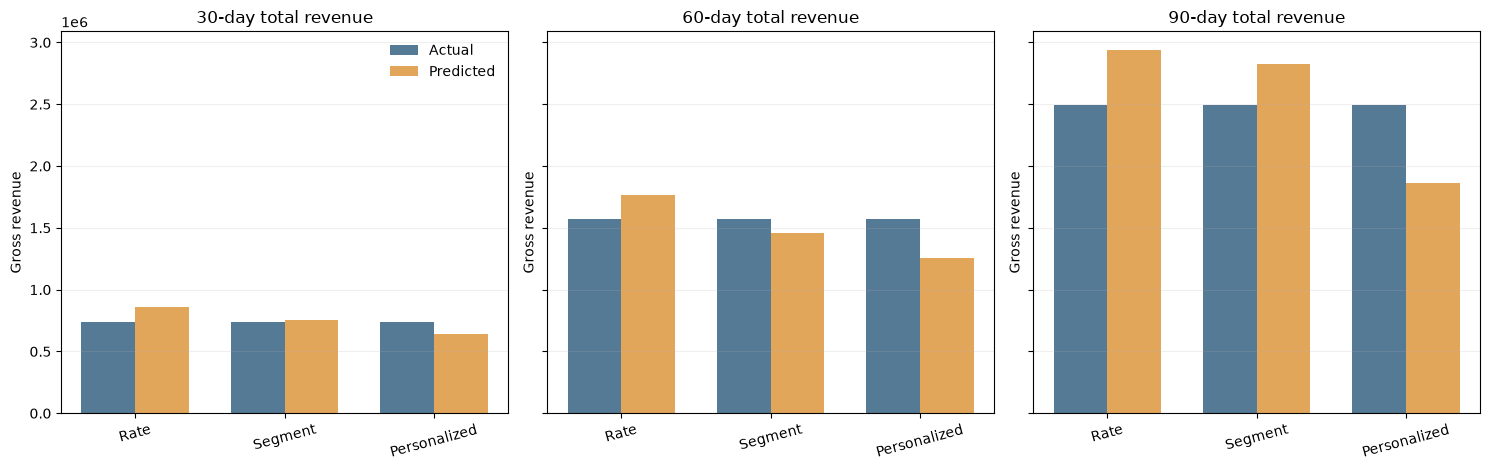

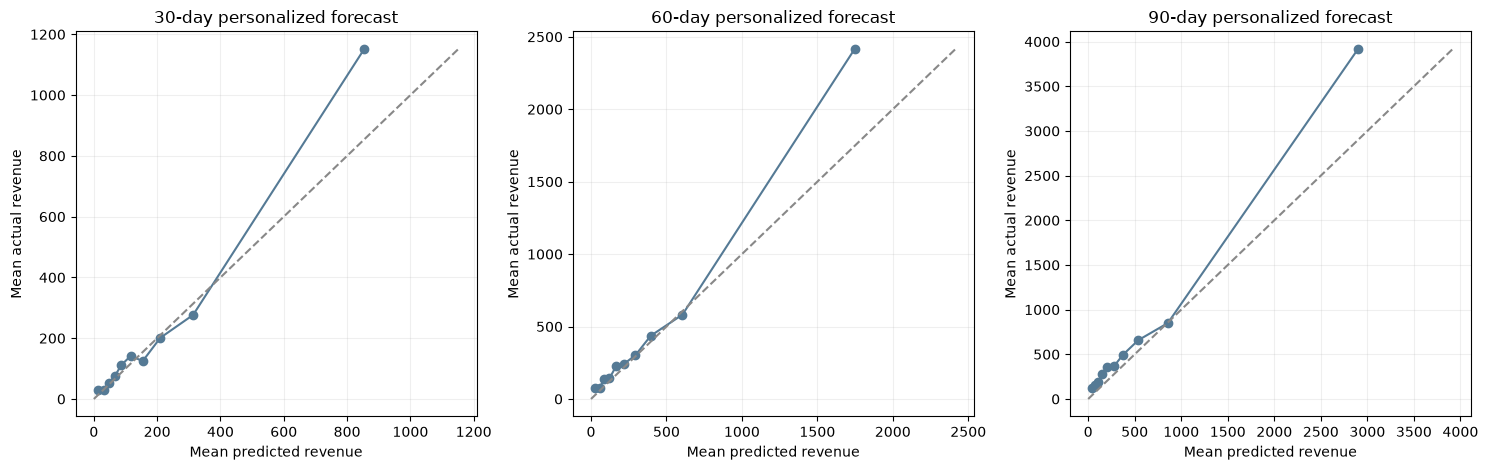

In [8]:
model_names = ["Historical spending-rate", "Segment-aware two-stage", "Personalized two-stage"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, horizon in zip(axes, sm.HORIZONS):
    summary = test_metrics.loc[test_metrics["horizon_days"].eq(horizon)].set_index("model")
    x = np.arange(len(model_names))
    predicted = [summary.loc[name, "total_predicted_revenue"] for name in model_names]
    actual = [summary.loc[name, "total_actual_revenue"] for name in model_names]
    width = 0.36
    ax.bar(x - width / 2, actual, width, label="Actual", color="#557a95")
    ax.bar(x + width / 2, predicted, width, label="Predicted", color="#e2a65b")
    ax.set_title(f"{horizon}-day total revenue")
    ax.set_xticks(x, ["Rate", "Segment", "Personalized"], rotation=15)
    ax.set_ylabel("Gross revenue")
    ax.grid(axis="y", alpha=0.2)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_predicted_vs_actual_totals.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=False, sharey=False)
for ax, horizon in zip(axes, sm.HORIZONS):
    subset = aggregate_calibration.loc[
        aggregate_calibration["horizon_days"].eq(horizon)
        & aggregate_calibration["model"].eq("Personalized two-stage")
    ]
    ax.plot(subset["mean_predicted_revenue"], subset["mean_actual_revenue"], marker="o", color="#557a95")
    upper = max(subset["mean_predicted_revenue"].max(), subset["mean_actual_revenue"].max())
    ax.plot([0, upper], [0, upper], linestyle="--", color="#888888")
    ax.set(title=f"{horizon}-day personalized forecast", xlabel="Mean predicted revenue", ylabel="Mean actual revenue")
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "personalized_revenue_calibration.png", dpi=160)
plt.show()

## 8. Save inference artifacts and evaluation outputs

The customer forecast export contains predictions only. Observed future revenue and purchase outcomes are saved in a separate evaluation-only file. The inference bundle accepts historical features and matching purchase probabilities without requiring a notebook.

In [9]:
all_forecasts = pd.concat([validation_forecasts, test_forecasts], ignore_index=True)
all_actuals = pd.concat([validation_actuals, test_actuals], ignore_index=True)
assert not set(sm.FORBIDDEN_FEATURES).intersection(sm.FEATURE_COLUMNS)
assert all(np.isfinite(all_forecasts["predicted_expected_revenue"]))
assert (all_forecasts["predicted_expected_revenue"] >= 0).all()
assert not set(all_actuals.columns).intersection(all_forecasts.columns) - {
    sm.CUSTOMER_ID, sm.CUTOFF_COL, "split_role", "horizon_days"
}

metadata = sm.make_metadata(
    horizon_models,
    purchase_model_metadata=purchase_metadata,
    split_files={h: f"data/processed/temporal/predictive_splits_{h}d.csv" for h in sm.HORIZONS},
)
metadata["test_cohort_customers"] = int(len(feature_frames[90]["TEST"]))
spending_bundle = {"metadata": metadata, "horizon_models": horizon_models}
model_path = sm.save_spending_artifacts(spending_bundle, MODEL_DIR)

with (MODEL_DIR / "feature_schema.json").open("w", encoding="utf-8") as f:
    json.dump({
        "feature_columns": list(sm.FEATURE_COLUMNS),
        "numeric_predictors": list(sm.NUMERIC_FEATURES),
        "categorical_predictors": list(sm.CATEGORICAL_FEATURES),
        "forbidden_predictors": sorted(sm.FORBIDDEN_FEATURES),
    }, f, indent=2)

validation_selection_metrics.to_csv(OUTPUT_DIR / "validation_model_selection.csv", index=False)
validation_metrics.to_csv(OUTPUT_DIR / "validation_expected_revenue_metrics.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "test_expected_revenue_metrics.csv", index=False)
validation_conditional_metrics.to_csv(OUTPUT_DIR / "validation_conditional_spending_metrics.csv", index=False)
test_conditional_metrics.to_csv(OUTPUT_DIR / "test_conditional_spending_metrics.csv", index=False)
all_forecasts.to_csv(OUTPUT_DIR / "customer_expected_revenue_predictions.csv", index=False)
all_actuals.to_csv(OUTPUT_DIR / "evaluation_actuals.csv", index=False)
performance_by_group.to_csv(OUTPUT_DIR / "test_performance_by_group.csv", index=False)
aggregate_calibration.to_csv(OUTPUT_DIR / "test_aggregate_calibration.csv", index=False)
extreme_sensitivity.to_csv(OUTPUT_DIR / "test_extreme_spending_sensitivity.csv", index=False)

# Reload the notebook-free inference artifact and verify deterministic forecasts.
reloaded = sm.load_spending_artifacts(MODEL_DIR)
for horizon in sm.HORIZONS:
    reloaded_predictions = sm.predict_expected_revenue(
        {"metadata": reloaded["metadata"], "horizon_models": {horizon: reloaded["horizon_models"][horizon]}},
        feature_frames[horizon]["TEST"],
        test_purchase_predictions[horizon],
    )
    expected = test_wide_predictions[horizon]
    numeric_columns = [column for column in expected if column not in (sm.CUSTOMER_ID, sm.CUTOFF_COL)]
    np.testing.assert_allclose(reloaded_predictions[numeric_columns], expected[numeric_columns], rtol=0, atol=1e-10)

print(f"Saved spending bundle: {model_path}")
print(f"Forecast-only rows: {len(all_forecasts):,}; evaluation-only actual rows: {len(all_actuals):,}")
print("Reload check: identical expected revenue and conditional spending forecasts.")

Saved spending bundle: /home/runner/workspace/OELP_project/models/spending_model/spending_models.joblib
Forecast-only rows: 56,862; evaluation-only actual rows: 18,954
Reload check: identical expected revenue and conditional spending forecasts.


In [10]:
test_summary = test_metrics.pivot(
    index="horizon_days", columns="model",
    values=["mae", "rmse", "mean_forecast_bias", "total_predicted_revenue", "total_actual_revenue", "aggregate_calibration_ratio"],
)
display(test_summary)
print("Selected conditional model and alpha by horizon:")
for horizon in sm.HORIZONS:
    fitted = horizon_models[horizon]["personalized_conditional"]
    conditional = test_conditional_metrics.loc[test_conditional_metrics["horizon_days"].eq(horizon)]
    best = conditional.sort_values("rmse").iloc[0]
    print(
        f"{horizon}d: Ridge alpha={fitted['alpha']:g}; "
        f"best conditional purchaser RMSE={best['model']} ({best['rmse']:.2f}); "
        f"smearing={fitted['smearing_factor']:.4f}."
    )
print("\nAll customer histories and future actuals remain in primary metrics; the top-1% analysis is sensitivity-only.")
print("Notebook 06 TEST prediction files were not reused. Joint forecasts use fresh predictions on matching cutoffs.")

mae                         \
model        Historical spending-rate Personalized two-stage   
horizon_days                                                   
30                         296.354744             243.080370   
60                         496.243546             383.753743   
90                         752.391950             547.382694   

                                                         rmse  \
model        Segment-aware two-stage Historical spending-rate   
horizon_days                                                    
30                        283.880765               945.387967   
60                        496.651829              1707.895769   
90                        836.261706              2487.427421   

                                                             \
model        Personalized two-stage Segment-aware two-stage   
horizon_days                                                  
30                       871.237501             1012.468915   
60                      1466.051568             1870.148304   
90                      2111.733507             2881.399300   

                   mean_forecast_bias                         \
model        Historical spending-rate Personalized two-stage   
horizon_days                                                   
30                          34.910845             -30.048386   
60                          57.754093             -92.410682   
90                         132.528122            -187.861456   

                                      total_predicted_revenue  \
model        Segment-aware two-stage Historical spending-rate   
horizon_days                                                    
30                          3.343399             8.584759e+05   
60                        -32.744216             1.763483e+06   
90                         97.257793             2.942544e+06   

                                                             \
model        Personalized two-stage Segment-aware two-stage   
horizon_days                                                  
30                     6.393684e+05            7.519989e+05   
60                     1.256977e+06            1.458232e+06   
90                     1.861870e+06            2.823577e+06   

                 total_actual_revenue                         \
model        Historical spending-rate Personalized two-stage   
horizon_days                                                   
30                         740721.591             740721.591   
60                        1568678.512            1568678.512   
90                        2495526.203            2495526.203   

                                     aggregate_calibration_ratio  \
model        Segment-aware two-stage    Historical spending-rate   
horizon_days                                                       
30                        740721.591                    1.158972   
60                       1568678.512                    1.124184   
90                       2495526.203                    1.179127   

                                                             
model        Personalized two-stage Segment-aware two-stage  
horizon_days                                                 
30                         0.863170                1.015225  
60                         0.801297                0.929593  
90                         0.746083                1.131455

Selected conditional model and alpha by horizon:
30d: Ridge alpha=0.1; best conditional purchaser RMSE=Personalized conditional (1514.97); smearing=1.3083.
60d: Ridge alpha=10; best conditional purchaser RMSE=Personalized conditional (2074.41); smearing=1.2823.
90d: Ridge alpha=0.1; best conditional purchaser RMSE=Personalized conditional (2737.05); smearing=1.3416.

All customer histories and future actuals remain in primary metrics; the top-1% analysis is sensitivity-only.
Notebook 06 TEST prediction files were not reused. Joint forecasts use fresh predictions on matching cutoffs.


## 9. Interpretation and limitations

- The forecasts are historical backtests on one year of UK retail transactions and are not causal intervention estimates.
- The 30/60/90-day spending models have different outcome-matured TRAIN and VAL cutoffs. Test customers share the 2010-09-10 cutoff; the feature transforms and historical segment labels remain horizon-specific as defined by Notebook 05.
- Notebook 06 supplies validation/test purchase probabilities only. Those probabilities are regenerated from its saved model and joined by exact customer ID and cutoff; its TEST prediction CSV is not reused. No Notebook 06 probabilities are used to fit the spending models.
- The historical-rate baseline is a direct unconditional benchmark. Segment-aware and personalized models use the two-stage purchase-probability times conditional-spending expectation.
- The fitted inference bundle requires cutoff-time historical features and aligned personalized purchase probabilities. Actual future outcomes are only for retrospective evaluation and are never returned by inference.

Run the final cell to execute the synthetic edge-case test suite.

In [11]:
test_result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "tests/test_spending_model.py"],
    cwd=PROJECT_ROOT,
    check=True,
    capture_output=True,
    text=True,
)
print(test_result.stdout)
print("Synthetic edge-case checks completed successfully.")

........                                                                 [100%]
8 passed in 4.18s

Synthetic edge-case checks completed successfully.
